### KNN regression - Housing data example

**This was based on the Random Forest regression -example!**

In [157]:
# these are usual imports in a classic ML pipeline for Regression
# pip install numpy
# pip install pandas
# pip install seaborn
# pip install scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# we can import the random forest algorithms from scikit-learn's ensemble -features
from sklearn.neighbors import KNeighborsRegressor

from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler

### STEP 1 - Load the data

In [158]:
# load the data
df = pd.read_csv("Housing.csv")

# let's see the first 5 rows
# there's only 30 rows in total, so this is only a demonstration
# on how to use scikit-learn, the dataset itself is not very useful
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


### STEP 2: Basic data checks, duplicates or missing values (NaN)?

In [159]:
df.columns

Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='str')

If your data has text categories (binary, ordinal, nominal), they have to be processed CORRECTLY in this phase as well.

In [160]:
# do we have missing values? apparently not
# DATASET CAN'T HAVE ANY MISSING VALUES when passing the data
# to the machine learning algorithm
df.isna().sum()

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

In [161]:
# do we have duplicates
int(df.duplicated().sum())

0

***Case 1: Binary categories (only EXACTLY two options)***

In [162]:
# this just converts the value of column to 0 or 1
# factorize in pandas works too, but only one column at a time
from sklearn.preprocessing import LabelEncoder
variables = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
encoder = LabelEncoder()
df[variables] = df[variables].apply(encoder.fit_transform)

In [163]:
df

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,furnished
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,furnished
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,semi-furnished
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,furnished
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,1,0,1,0,0,2,0,unfurnished
541,1767150,2400,3,1,1,0,0,0,0,0,0,0,semi-furnished
542,1750000,3620,2,1,1,1,0,0,0,0,0,0,unfurnished
543,1750000,2910,3,1,1,0,0,0,0,0,0,0,furnished


***Case 2: Ordinal categories (categories that have and order/rank => can be compared)***

A working example is in the code comments below, if you need this code for ordinal categories.

In [164]:
# no ordinal categories in the dataset
# however, we could kinda try to treat the furnishing status like an ordinal
# but in this example, we consider it to be a nominal category

# check a later example with the diamonds data for the ordinal categories!

***Case 3: Nominal categories (categories that can't be compared numerically)***

In [165]:
# this makes multiple columns with the variable (Separate for yes/no)
from sklearn.preprocessing import OneHotEncoder
variables = ['furnishingstatus']

# use encoder
encoder = OneHotEncoder(sparse_output=False).set_output(transform="pandas")
one_hot_encoded = encoder.fit_transform(df[variables]).astype(int)
df = pd.concat([df,one_hot_encoded],axis=1).drop(columns=variables)

In [166]:
df

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_furnished,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,1,0,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,1,0,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,0,1,0
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,1,0,0
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,1,0,1,0,0,2,0,0,0,1
541,1767150,2400,3,1,1,0,0,0,0,0,0,0,0,1,0
542,1750000,3620,2,1,1,1,0,0,0,0,0,0,0,0,1
543,1750000,2910,3,1,1,0,0,0,0,0,0,0,1,0,0


In [167]:
# see the materials (Rovaniemi/Oulu/Helsinki), we can make a small optimization
# => remove the last new boolean variable, since it's going to be represented
# by a straight line of zeroes
df = df.drop("furnishingstatus_unfurnished", axis=1)

In [168]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_furnished,furnishingstatus_semi-furnished
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,1,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,1,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,0,1
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,1,0
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,1,0


**All data is now prepared and in ALL NUMERIC format (this data didn't have any categories)**

### STEP 3: X/y and train/test -split

In [169]:
df.columns

Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus_furnished',
       'furnishingstatus_semi-furnished'],
      dtype='str')

In [170]:
# first step, we split our data into SUPPORT variables and the TARGET variable
# X => support variables, y => target variable

# X => list of support variables that the model uses
# while predicting the target variable with the model
X = df.drop("price", axis=1)

# our target variable y
y = df['price']

In [171]:
# secondly, train/test -split with scikit-learn's helper function
# 0.3 for testing => 30% of the data is reserved for testing purposes (used for metrics later)
# and based on that => it's deduced that 70% will be in the training data

# you can also define the random state, which is sometimes useful
# if you want to "lock down" all the randomness in this part to get same results every time
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1718951)

**Find the optimal k-value (regression -version)**

Based on iterations, best k-value is this:
17


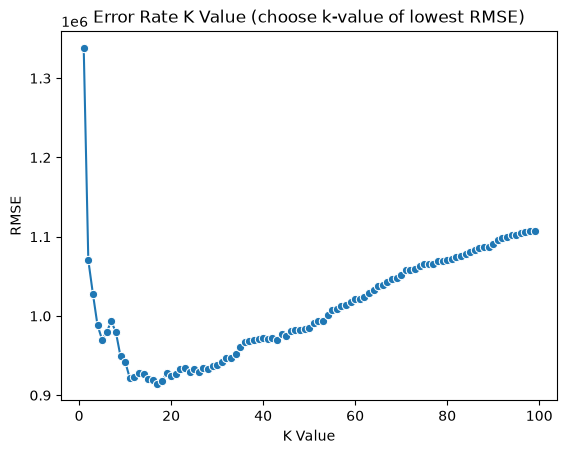

In [172]:
# REGRESSION VERSION
# adjust this to 50 or even 150 if you have lots of data rows
max_iterations = 100

# list to save the error values in the loop
error = []

# the default metric in scikit-learn
metric_selection = "euclidean"
weight_selection = "uniform"
algorithm_selection = "auto"

# Calculating error for K values between 1 and 40
for i in range(1, max_iterations):

    # try with current k-value, train the model and make a test prediction
    knn = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=i, metric=metric_selection, weights=weight_selection, algorithm=algorithm_selection))
    knn.fit(X_train, y_train)
    pred_i = knn.predict(X_test)
    
    # save the error value for this k-value
    error.append(np.sqrt(metrics.mean_squared_error(y_test, pred_i)))
    
# plot all the k-values and their error values
sns.lineplot(x=range(1, max_iterations), y=error, marker='o')
plt.title('Error Rate K Value (choose k-value of lowest RMSE)')
plt.xlabel('K Value')
plt.ylabel('RMSE')

# choose best k-value based on metrics
# we have to add +1 to k-value, since argmin() returns an index
# which starts from 0, but k-values start from 1
print("Based on iterations, best k-value is this:")
k_value = np.argmin(error) + 1
print(k_value)

### STEP 4: Create and train the ML model

**NOTE! no need to use TransformedTargetRegressor for Random Forest (as in SVR)**

In [173]:
# create the pipeline with our model with the data
# use pipeline to scale the X-values automatically (StandardScaler)

from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.preprocessing import QuantileTransformer
from sklearn.preprocessing import RobustScaler

# make_pipeline(StandardScaler(), svm.SVR())
# model = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k_value, metric=metric_selection, weights=weight_selection, algorithm=algorithm_selection))

# model = TransformedTargetRegressor(
#     regressor=make_pipeline(
#         StandardScaler(),
#         KNeighborsRegressor(
#             n_neighbors=k_value,
#             metric=metric_selection,
#             weights=weight_selection,
#             algorithm=algorithm_selection
#         )
#     ),
#     transformer=PowerTransformer(method='yeo-johnson')
# )

# model = TransformedTargetRegressor(
#     regressor=make_pipeline(
#         StandardScaler(),
#         KNeighborsRegressor(
#             n_neighbors=k_value,
#             metric=metric_selection,
#             weights=weight_selection,
#             algorithm=algorithm_selection
#         )
#     ),
#     transformer=QuantileTransformer(
#         n_quantiles=100,
#         output_distribution='normal',
#         random_state=42
#     )
# )

# model = TransformedTargetRegressor(
#     regressor=make_pipeline(
#         StandardScaler(),
#         KNeighborsRegressor(
#             n_neighbors=k_value,
#             metric=metric_selection,
#             weights=weight_selection,
#             algorithm=algorithm_selection
#         )
#     ),
#     transformer=QuantileTransformer(
#         n_quantiles=100,
#         output_distribution='normal',
#         random_state=42
#     )
# )

# this is pretty good!
model = TransformedTargetRegressor(
    regressor=make_pipeline(
        StandardScaler(),
        KNeighborsRegressor(
            n_neighbors=k_value,
            metric=metric_selection,
            weights=weight_selection,
            algorithm=algorithm_selection
        )
    ),
    func=np.sqrt,
    inverse_func=np.square
)

# model = TransformedTargetRegressor(
#     regressor=make_pipeline(
#         StandardScaler(),
#         KNeighborsRegressor(
#             n_neighbors=k_value,
#             metric=metric_selection,
#             weights=weight_selection,
#             algorithm=algorithm_selection
#         )
#     ),
#     func=lambda y: 1 / y,
#     inverse_func=lambda y: 1 / y
# )

# model = TransformedTargetRegressor(
#     regressor=make_pipeline(
#         StandardScaler(),
#         KNeighborsRegressor(
#             n_neighbors=k_value,
#             metric=metric_selection,
#             weights=weight_selection,
#             algorithm=algorithm_selection
#         )
#     ),
#     transformer=RobustScaler()
# )


# train the model normally
model.fit(X_train, y_train)

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step....int64(17)))])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'sqrt'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'square'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](13,)","['area','bedrooms','bathrooms',...,'prefarea','furnishingstatus_furnished', 'furnishingstatus_semi-furnished']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,13
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step....int64(17)))])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('kneighborsregressor', ...)]"


### STEP 5: Error and performance metrics

In [174]:
# we need to create test predictions based on our earlier reserved test dataset
# this data has never been seen by the model by now
predictions = model.predict(X_test)

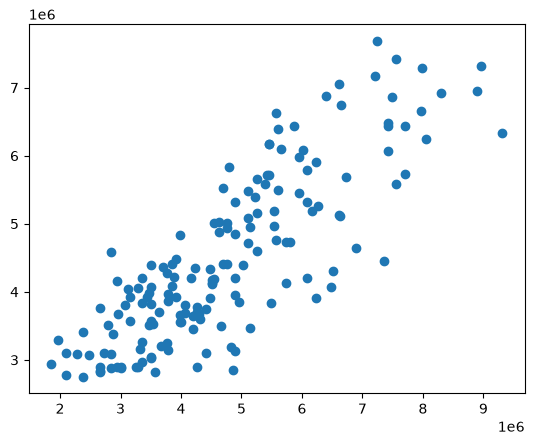

In [175]:
# let's plot how far the predictions are from the real target values (y)
# in the test dataset

# if the values follow a diagonal line (from bottom left to top right)
# => we have good predictions with the model
# we basically compare the predicted values to the actual true values 
# and compare the differences
plt.scatter(y_test, predictions)

In [176]:
# MAE = Mean Absolute Error
mae = metrics.mean_absolute_error(y_test, predictions)
print("MAE: ")
print(f"{round(mae, 2)} $")

# MSE = Mean squared error
mse = metrics.mean_squared_error(y_test, predictions)
print("\nMSE: ")
print(f"{round(mse, 2)} $^2")

# RMSE = Root Mean Square Error
rmse = np.sqrt(mse)
print("\nRMSE: ")
print(f"{round(rmse, 2)} $")

# R-square (or R2) - how well the model describes the original dataset
# 1 => model describes the data perfectly
# 0 => model doesn't describe the data at all
r2 = metrics.r2_score(y_test, predictions)
print("\nR-squared: ")
print(f"{round(r2, 2)}")

MAE: 
715797.7 $

MSE: 
872629592961.17 $^2

RMSE: 
934146.45 $

R-squared: 
0.66


In [ ]:
# still worse than without the transformation

# MAE: 
# 710670.76 $

# MSE: 
# 836421508866.86 $^2

# RMSE: 
# 914560.83 $

# R-squared: 
# 0.67

C:\Users\tuomas.valtanen\AppData\Local\Temp\ipykernel_12468\2033131320.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot((y_test - predictions))


<Axes: xlabel='price', ylabel='Density'>

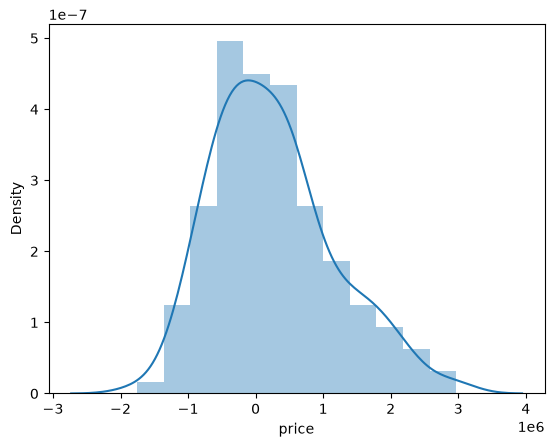

In [178]:
# if the prediction distribution is far from standard normal distribution
# then the model is not probably good enough (should reflect the metrics above)

# distplot is deprecated and will be removed in future seaborn versions
# but no direct replacement has been created so far
sns.distplot((y_test - predictions))

### STEP 6: Testing/using the model in practice (inference)

In [179]:
X.columns

Index(['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom',
       'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea',
       'furnishingstatus_furnished', 'furnishingstatus_semi-furnished'],
      dtype='str')

In [180]:
df.head(3)

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_furnished,furnishingstatus_semi-furnished
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,1,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,1,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,0,1


In [181]:
# usually for the GUI application, we save the model-object / variable 
# into a file (by using joblib-module)
# and in the GUI application => we load the save model from the file
# and use the model just like here below

# let's create a Python -dictionary, containing our test values
# THE VARIABLE NAMES HAVE TO MATCH WITH THE ORIGINAL DATASET
tester_row = {
    'area': 7420, 
    'bedrooms': 4, 
    'bathrooms': 2, 
    'stories': 3, 
    'mainroad': 1, 
    'guestroom': 0,
    'basement': 0, 
    'hotwaterheating': 0, 
    'airconditioning': 1, 
    'parking': 2, 
    'prefarea': 1,
    'furnishingstatus_furnished': 1, 
    'furnishingstatus_semi-furnished': 0
}

# convert to pandas format
tester_row = pd.DataFrame([tester_row])

In [182]:
# get the output/result from the model
# based on the user's given new data (above code cell)
result = model.predict(tester_row)[0]

print()
print("Predicted/estimated house market value based on given variables:")
print(f"$ {round(float(result), 2)}")
print("------------------------------")


Predicted/estimated house market value based on given variables:
$ 7254403.65
------------------------------
